# 02 · Data

lenscape keeps photometry in a `Data` object: several data sets (telescopes, filters), each with its own source
and blend flux in every fit. This notebook shows how to load, combine, cut and normalise data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
import os, tempfile

## KMTNet pySIS files

`read_pysis` reads KMTNet pySIS files (HJD, difference flux, flux error, mag, mag error, ...), one data set per
file. The time column is full HJD in some files and HJD − 2450000 in others; both are recognised.
`datasets.kmtnet` downloads and reads them in one step.

In [2]:
data = lenscape.datasets.kmtnet("KMT-2022-BLG-0114")
print(data)
print("sets:", data.names, "| points per set:", [len(s) for s in data.slices])
print("arrays:", data.t[:3], data.f[:3], data.e[:3], data.idx[:3])

Data(2371 points, t 9630.85 .. 9874.29, sets {'KMTA22': 481, 'KMTC22': 1146, 'KMTS22': 744})
sets: ['KMTA22', 'KMTC22', 'KMTS22'] | points per set: [481, 1146, 744]
arrays: [9638.25216 9641.22975 9644.21087] [ -1737.8225  -6653.9237 -15019.1745] [ 201.3201  520.0792 1009.6618] [0 0 0]


## Cuts

`window` keeps a time range, `select` any boolean mask; both return a new `Data`.

In [3]:
season = data.window(9600, 9720)
print(season)
kmtc_only = data.select(data.idx == data.names.index("KMTC22"))
print(kmtc_only)

Data(736 points, t 9630.85 .. 9719.90, sets {'KMTA22': 140, 'KMTC22': 417, 'KMTS22': 179})
Data(1146 points, t 9630.85 .. 9873.54, sets {'KMTA22': 0, 'KMTC22': 1146, 'KMTS22': 0})


## Arrays, text files and magnitudes

`Data.from_sets` builds a data set from arrays, `read_text` reads a text file (columns time, value, error; with
`mag=True` the values are magnitudes and are converted to fluxes). Here we write one telescope to a text file in
magnitudes and read it back.

In [4]:
k = season.idx == 0
mag = 22 - 2.5 * np.log10(np.abs(season.f[k]) + 1e3)           # some magnitudes for the example
emag = 1.0857 * season.e[k] / (np.abs(season.f[k]) + 1e3)
path = os.path.join(tempfile.mkdtemp(), "example.dat")
np.savetxt(path, np.c_[season.t[k] + 2450000, mag, emag], header="HJD  I  sigma_I")

t, f, e = lenscape.read_text(path, cols=(0, 1, 2), t_offset=2450000, mag=True)
combined = lenscape.Data.from_sets({"from_text": (t, f, e),
                                    "KMTC22": (season.t[season.idx == 1], season.f[season.idx == 1],
                                               season.e[season.idx == 1])})
combined

Data(557 points, t 9630.85 .. 9719.90, sets {'from_text': 140, 'KMTC22': 417})

## Error bars

Two common normalisations:

* one factor per data set so that χ²/N = 1 at the best fit: `lenscape.error_factors(data, p)`, then
  `data.scale_errors(k)`;
* the form of Yee et al. (2012), σ′ = k √(σ² + σ_min²) in magnitudes: `lenscape.data.rescale(flux_err, mag_err, k,
  sigma_min)`.

In [5]:
p = np.array([9657.77, -0.0254, 35.5, 0.0020, -2.398, 4.41, -3.3])        # a solution of this event
k = lenscape.error_factors(season, p)
print("factors:", {n: round(v, 2) for n, v in k.items()})
scaled = season.scale_errors(k)
print("after scaling:", {n: round(v, 2) for n, v in lenscape.error_factors(scaled, p).items()})

factors: {'KMTA22': 3.04, 'KMTC22': 1.44, 'KMTS22': 1.91}
after scaling: {'KMTA22': 1.0, 'KMTC22': 1.0, 'KMTS22': 1.0}


In [6]:
fe = season.e[:5]
emag = 1.0857 * fe / np.abs(season.f[:5] + 2000)
print(lenscape.data.rescale(fe, emag, k=1.2, smin=0.01))

[ 241.60149879  626.21127995 1220.10944277  281.5107897   406.03411397]


## Outliers

Residuals in units of the error bars, `model.residuals(backend, p, data)`, give a simple clipping criterion.

removed 1 points beyond 5 sigma


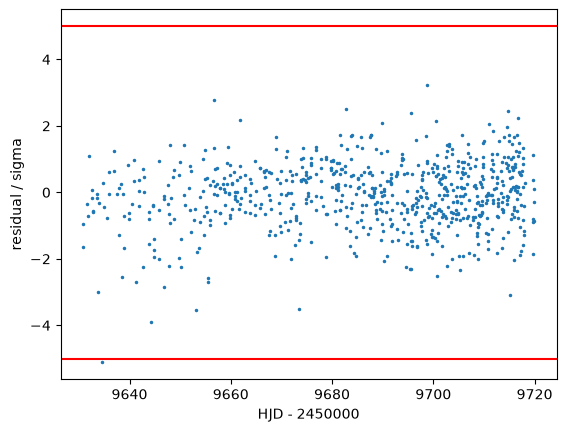

In [7]:
backend = lenscape.make_backend(config.REFINE_BACKEND)
r = lenscape.model.residuals(backend, p, scaled)
clean = scaled.select(np.abs(r) < 5)
print(f"removed {len(scaled) - len(clean)} points beyond 5 sigma")
plt.plot(scaled.t, r, ".", ms=3); plt.axhline(5, c="r"); plt.axhline(-5, c="r")
plt.xlabel("HJD - 2450000"); plt.ylabel("residual / sigma");

## Binning the wings (speed option)

For maps, points far from the event (|t − t0| > tE) are grouped per night and replaced by their sums; χ² stays
exact for a model that is linear in time within a night. `lattice()` does this automatically when it is given
the best fit; `bin_wings` does it by hand.

In [8]:
binned = lenscape.data.bin_wings(clean, t0=p[0], tE=p[2])
print(f"{len(clean)} points, {len(binned.t_eval)} model evaluations after binning")
print("chi2 unbinned %.2f, binned %.2f" % (lenscape.model.chi2(backend, p, clean), lenscape.model.chi2(backend, p, binned)))

735 points, 507 model evaluations after binning
chi2 unbinned 709.88, binned 709.88
